# Retornos diários dos itens CS:GO

Este caderno descreve o retorno e o risco dos itens. A ordem vai do item para o conjunto: as estatísticas
por item, a distribuição de todos os retornos e a divisão por raridade e por faixa de preço. O retorno
diário usa só dois preços observados em dias seguidos. Nenhum preço é preenchido: preencher criaria
retornos zero artificiais e um salto quando o próximo preço chega.

In [1]:
from argparse import ArgumentParser
from pathlib import Path

import altair as alt
import polars as pl
from great_tables import GT
from helpers.export import inline_table_styles, write_outputs
from helpers.formatting import DEC_MARK, SEP_MARK, cap_text
from helpers.params import load_params
from helpers.paths import repo
from helpers.returns import RETURN_COLUMNS, return_distribution, return_statistics
from helpers.runtime import notebook_arguments
from helpers.schemas import read_table
from helpers.segments import price_segment, rarity_segment, segment_summary

In [2]:
# GitHub shows PNG output but not Vega-Lite.
alt.renderers.enable("png")

# GitHub drops style blocks, so the tables keep their styles inline.
inline_table_styles()

WIDE_TABLES = frozenset({"returns", "distribution", "rarity", "price_buckets"})

CAP_TEXT = cap_text()

LABEL_MAP = {"rest": "Restante", "overall": "Geral"}

DISTRIBUTION_LABELS = {"capped": f"Limitado ({CAP_TEXT})", "raw": "Bruto"}

PERCENT_COLUMNS = ["mean", "geometric_mean", "std", "p01", "p05", "p50", "p95", "p99", "share_above_half"]

## Argumentos da linha de comando

In [3]:
parser = ArgumentParser(description="Retornos: estatísticas por item, distribuição e segmentos.")
parser.add_argument("--prices", type=Path, default=repo() / "files/prices.parquet", help="Preços diários limpos.")
parser.add_argument("--tables", type=Path, default=repo() / "output/tables", help="Pasta para os arquivos das tabelas.")
parser.add_argument("--images", type=Path, default=repo() / "output/images", help="Pasta para os gráficos.")
args = parser.parse_args(notebook_arguments())

In [4]:
prices = read_table("prices", args.prices)

## Resumir retorno e risco por item

As estatísticas por item mostram risco e retorno diários. Só entram no ranking os itens com dias
suficientes, para que poucos pontos não dominem a lista. As linhas Restante e Geral mantêm os demais
itens na conta. As razões de Sharpe e Sortino ficam diárias, sem anualização, porque a autocorrelação
dos retornos invalida a regra da raiz quadrada.

In [5]:
returns = return_statistics(prices)
returns_text = returns.with_columns(pl.col("name").replace(LABEL_MAP))
# The last two rows pool the remaining assets and all assets. Their day count is an average, not a whole number.
asset_rows = list(range(returns_text.height - 2))
pooled_rows = [returns_text.height - 2, returns_text.height - 1]

returns_gt = (
    GT(returns_text)
    .tab_header(title="Estatísticas dos Retornos — Itens CS:GO")
    .fmt_percent(columns=RETURN_COLUMNS, decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_number(columns=["n_days"], rows=asset_rows, decimals=0, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_number(columns=["n_days"], rows=pooled_rows, decimals=1, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_number(columns=["sharpe", "sortino"], decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .tab_spanner(label="Retornos", columns=RETURN_COLUMNS)
    .cols_label(
        name="Item",
        mean_return="Média",
        median_return="Mediana",
        geometric_return="Composto",
        min_return="Mínimo",
        max_return="Máximo",
        std_return="DP",
        negative_returns_std="DP (negativos)",
        n_days="Dias",
        sharpe="Sharpe",
        sortino="Sortino",
    )
    .cols_hide("rank_n")
    .tab_source_note(
        "DP: desvio padrão. Razões diárias com taxa livre de risco zero. "
        "Sharpe: média sobre o DP dos retornos. Sortino: média sobre o DP dos dias negativos. "
        f"Retornos limitados em {CAP_TEXT}. Ranking pelo retorno composto entre itens com 400 dias ou mais de retorno. "
        "Restante e Geral reúnem todos os retornos diários dos itens."
    )
)
returns_gt

DP: desvio padrão. Razões diárias com taxa livre de risco zero. Sharpe: média sobre o DP dos retornos. Sortino: média sobre o DP dos dias negativos. Retornos limitados em 500%. Ranking pelo retorno composto entre itens com 400 dias ou mais de retorno. Restante e Geral reúnem todos os retornos diários dos itens.


## Descrever a distribuição dos retornos

Comparar o retorno limitado com o bruto mostra o efeito do limite sobre a média e o desvio
padrão. Também revela caudas pesadas. O limite não pode ser apertado: com teto de 100%, a soma dos
retornos logarítmicos de um item perdia mais de 90% da variação total do preço, porque muitos itens
dobram de preço de uma vez e de forma permanente. A análise de sensibilidade mostra outros tetos.

In [6]:
distribution = return_distribution(prices)
distribution_text = distribution.with_columns(
    pl.col("label").replace_strict(DISTRIBUTION_LABELS, return_dtype=pl.String)
)

distribution_gt = (
    GT(distribution_text)
    .tab_header(title="Distribuição dos Retornos Diários — CS:GO")
    .fmt_percent(columns=PERCENT_COLUMNS, decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_number(columns=["skewness", "excess_kurtosis"], decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_integer(columns=["n"], sep_mark=SEP_MARK)
    .cols_label(
        label="Retorno",
        n="Observações",
        mean="Média",
        geometric_mean="Composto",
        std="DP",
        skewness="Assimetria",
        excess_kurtosis="Curtose em excesso",
        p01="P1",
        p05="P5",
        p50="P50",
        p95="P95",
        p99="P99",
        share_above_half="|r| > 50%",
    )
    .tab_source_note(
        "DP: desvio padrão. Retornos de todos os itens reunidos. O retorno bruto não tem limite. "
        f"O limite de {CAP_TEXT} reduz a média e o desvio padrão. Com ruído de preço, a média aritmética supera "
        "a mediana e o retorno composto."
    )
)
distribution_gt

"DP: desvio padrão. Retornos de todos os itens reunidos. O retorno bruto não tem limite. O limite de 500% reduz a média e o desvio padrão. Com ruído de preço, a média aritmética supera a mediana e o retorno composto."


A escala logarítmica do histograma mantém visíveis as caudas raras. O teto do eixo para o retorno bruto
evita que poucos valores extremos escondam o centro da distribuição.

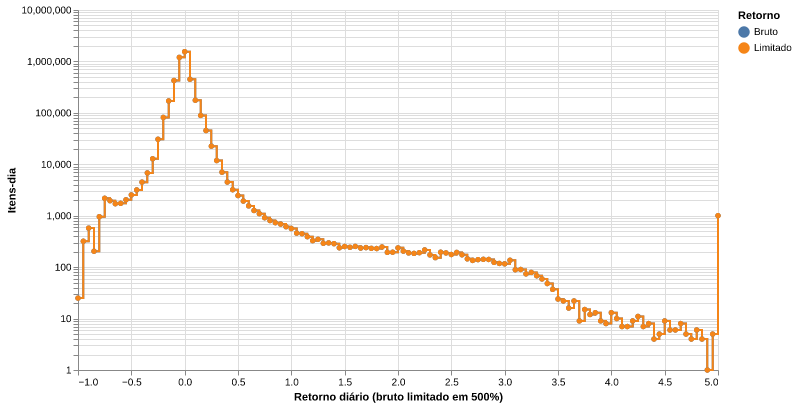

In [7]:
chart_params = load_params()["charts"]
bin_width = chart_params["bin_width"]
# Cap the raw return at the chart ceiling so a few extreme values do not hide the center.
raw_returns = prices["raw_return"].clip(upper_bound=chart_params["raw_ceiling"])
return_series = {"Limitado": prices["return"], "Bruto": raw_returns}

return_bins = pl.concat(
    [
        pl.DataFrame({"retorno": series, "serie": label})
        .drop_nulls("retorno")
        .with_columns(((pl.col("retorno") / bin_width).floor() * bin_width).alias("faixa"))
        .group_by("serie", "faixa")
        .agg(pl.len().alias("itens_dia"))
        for label, series in return_series.items()
    ]
).sort("serie", "faixa")

returns_figure = (
    alt.Chart(return_bins)
    .mark_line(point=True, interpolate="step-after")
    .encode(
        x=alt.X("faixa:Q", title="Retorno diário (bruto limitado em 500%)"),
        y=alt.Y("itens_dia:Q", title="Itens-dia", scale=alt.Scale(type="log")),
        color=alt.Color("serie:N", title="Retorno"),
    )
    .properties(width=640, height=360)
)
returns_figure

## Comparar retornos por raridade e por faixa de preço

Raridade e faixa de preço separam itens comuns e baratos de itens raros e caros. Glaus (2022) mostra
que o efeito de promoção é mais forte em itens comuns, que dominam um índice de peso igual.
Guede-Fernández et al. (2025) ligam raridade a liquidez. Um item aparece em mais de uma faixa de preço
quando o preço cruza a fronteira da faixa.

In [8]:
def segment_table(frame: pl.DataFrame, title: str, label: str, note: str) -> GT:
    """Build the table of one segment summary.

    Returns:
        The formatted table.

    """
    return (
        GT(frame.with_columns(pl.col("segment").cast(pl.String)))
        .cols_align("left", columns="segment")
        .tab_header(title=title)
        .fmt_integer(columns=["items", "item_days"], sep_mark=SEP_MARK)
        .fmt_number(columns=["median_price"], decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
        .fmt_percent(columns=["mean_return", "std_return"], decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
        .fmt_percent(columns=["zero_share"], decimals=1, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
        .cols_label(
            segment=label,
            items="Itens",
            item_days="Itens-dia",
            median_price="Preço mediano (US$)",
            mean_return="Média",
            std_return="DP",
            zero_share="Retorno zero",
        )
        .tab_source_note(note)
    )


rarity = segment_summary(prices, rarity_segment())
rarity_gt = segment_table(
    rarity,
    "Retornos Diários por Raridade — CS:GO",
    "Raridade",
    "DP: desvio padrão. Ordem pelo preço mediano. Os tipos de item usam escalas de raridade diferentes.",
)
rarity_gt

DP: desvio padrão. Ordem pelo preço mediano. Os tipos de item usam escalas de raridade diferentes.


In [9]:
price_buckets = segment_summary(prices, price_segment())
price_gt = segment_table(
    price_buckets,
    "Retornos Diários por Faixa de Preço — CS:GO",
    "Preço diário (US$)",
    "DP: desvio padrão. Um item entra em mais de uma faixa quando o preço cruza a fronteira.",
)
price_gt

DP: desvio padrão. Um item entra em mais de uma faixa quando o preço cruza a fronteira.


## Exportar tabelas LaTeX e gráficos PNG

In [10]:
tables = {
    "returns": returns_gt,
    "distribution": distribution_gt,
    "rarity": rarity_gt,
    "price_buckets": price_gt,
}

write_outputs(tables, {"returns_histogram": returns_figure}, args.tables, args.images, WIDE_TABLES)

Written /mnt/external/projects/thesis/output/tables/returns.tex
Written /mnt/external/projects/thesis/output/tables/distribution.tex
Written /mnt/external/projects/thesis/output/tables/rarity.tex
Written /mnt/external/projects/thesis/output/tables/price_buckets.tex
Written /mnt/external/projects/thesis/output/images/returns_histogram.png
